# HASTS206 Assignment 2: Part 3: Three-state Markov model

**All data are hypothetical (synthetic).** Run from the repository root. The first code cell runs the previous part (`part4_projections.ipynb`) so that all earlier variables exist.

In [ ]:
%run part4_projections.ipynb

## 3. Three-state continuous-time Markov model (Healthy, Ill, Dead)
### 3(a) State diagram, pooled intensities and generator matrix Q
Following the README: `exposure_py` and `initial_lives` are repeated on both destination rows of each district-origin pair. To avoid double counting I take **one copy per district-origin** (a `drop_duplicates` on `district_id, origin`) before pooling, while `transition_count` is summed over all rows.

Intensity estimate (occupancy-exposure, constant-hazard MLE): lambda_ij = (pooled jumps i to j) / (pooled person-years in origin state i).

In [27]:
# What this cell does: Counts exposure and initial lives once per district-origin, pools the jump
# counts, estimates the four transition intensities and builds the generator matrix Q.
origin_tbl = ins.drop_duplicates(['district_id', 'origin'])[['district_id', 'origin', 'exposure_py', 'initial_lives']]
naive_expo = ins.groupby('origin').exposure_py.sum()          # WRONG: double counts
expo = origin_tbl.groupby('origin').exposure_py.sum()          # correct
init = origin_tbl.groupby('origin').initial_lives.sum()
cnt = ins.groupby(['origin', 'destination']).transition_count.sum()
print('Pooled exposure (person-years): correct =', expo.to_dict(), '| naive double-counted =', naive_expo.to_dict())
print('Pooled initial lives (counted once per district-origin):', init.to_dict(), '| total =', int(init.sum()))
print('Pooled jump counts:'); print(cnt.to_string())

STATES = ['H', 'I', 'D']
def build_Q(c, e):
    Q = np.zeros((3, 3))
    Q[0, 1] = c[('H', 'I')] / e['H']; Q[0, 2] = c[('H', 'D')] / e['H']
    Q[1, 0] = c[('I', 'H')] / e['I']; Q[1, 2] = c[('I', 'D')] / e['I']
    Q[0, 0] = -Q[0, 1:].sum(); Q[1, 1] = -(Q[1, 0] + Q[1, 2])
    return Q
Q = build_Q(cnt, expo)
Qdf = pd.DataFrame(Q, index=STATES, columns=STATES)
print('\nGenerator matrix Q (per person-year), order H, I, D:'); print(Qdf.round(5).to_string())
print('\nRow sums:', Q.sum(axis=1))
off = Q - np.diag(np.diag(Q))
print('Off-diagonals all >= 0:', bool((off >= 0).all()), '| diagonals all <= 0:', bool((np.diag(Q) <= 0).all()), '| death row all zero (absorbing):', bool((Q[2] == 0).all()))
assert np.allclose(Q.sum(axis=1), 0) and (off >= 0).all()
rates = pd.DataFrame({'jumps': cnt, 'origin_exposure_py': [expo[o] for o, _ in cnt.index]})
rates['intensity_per_py'] = rates.jumps / rates.origin_exposure_py
rates['ci95_low'] = rates.intensity_per_py * (1 - 1.96 / np.sqrt(rates.jumps))
rates['ci95_high'] = rates.intensity_per_py * (1 + 1.96 / np.sqrt(rates.jumps))
rates

Pooled exposure (person-years): correct = {'H': 49764, 'I': 14417} | naive double-counted = {'H': 99528, 'I': 28834}
Pooled initial lives (counted once per district-origin): {'H': 20080, 'I': 3576} | total = 23656
Pooled jump counts:
origin  destination
H       D               895
        I              5152
I       D               970
        H              3533

Generator matrix Q (per person-year), order H, I, D:
        H       I      D
H -0.1215  0.1035 0.0180
I  0.2451 -0.3123 0.0673
D       0       0      0

Row sums: [3.46944695e-18 1.38777878e-17 0.00000000e+00]
Off-diagonals all >= 0: True | diagonals all <= 0: True | death row all zero (absorbing): True


**Notes: pooling and the generator matrix Q.**
- Counting each exposure once gives 49,764 healthy person-years and 14,417 ill person-years. Adding the repeated rows would give 99,528 and 28,834, which doubles the denominators and halves every rate.
- Intensities per person-year are: H to I 0.1035, H to D 0.0180, I to H (recovery) 0.2451 and I to D 0.0673. Death is 3.7 times as likely for someone who is ill as for someone who is healthy.
- **Checks:** every off-diagonal is non-negative, every diagonal is non-positive, every row sums to zero, and the D row is zero (death is absorbing). The pooled starting group is 20,080 healthy and 3,576 ill (23,656 lives).

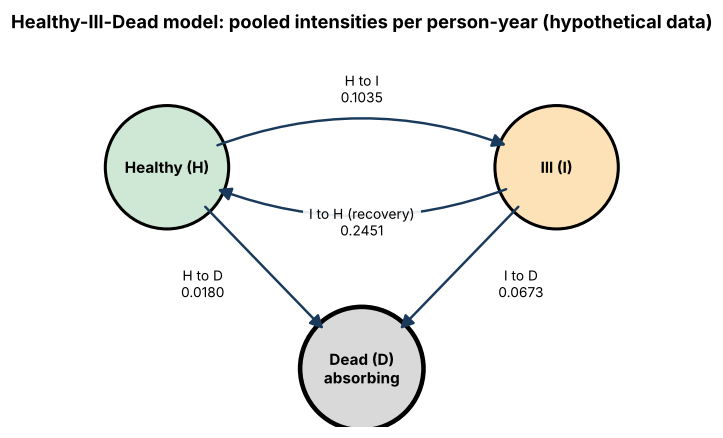

In [28]:
# What this cell does: Draws the healthy-ill-dead state diagram with the estimated intensities on each
# arrow.
fig, ax = plt.subplots(figsize=(8.5, 4.6)); ax.set_xlim(0, 10); ax.set_ylim(0, 6); ax.set_aspect('equal'); ax.axis('off')
pos = {'H': (2, 4), 'I': (8, 4), 'D': (5, 0.9)}
colr = {'H': '#cfe8d5', 'I': '#fde2b8', 'D': '#d9d9d9'}
names = {'H': 'Healthy (H)', 'I': 'Ill (I)', 'D': 'Dead (D)\nabsorbing'}
for s, (x, y) in pos.items():
    ax.add_patch(Circle((x, y), .95, fc=colr[s], ec='k', lw=2 if s != 'D' else 3)); ax.text(x, y, names[s], ha='center', va='center', fontsize=10, fontweight='bold')
def arrow(a, b, rad, label, lx, ly):
    ar = FancyArrowPatch(pos[a], pos[b], connectionstyle=f'arc3,rad={rad}', arrowstyle='-|>', mutation_scale=18, lw=1.6, shrinkA=36, shrinkB=36, color='#1a3a5c'); ax.add_patch(ar)
    ax.text(lx, ly, label, ha='center', fontsize=9, bbox=dict(fc='white', ec='none', alpha=.9))
arrow('H', 'I', -.25, f'H to I\n{Q[0,1]:.4f}', 5, 5.0)
arrow('I', 'H', -.25, f'I to H (recovery)\n{Q[1,0]:.4f}', 5, 2.95)
arrow('H', 'D', .0, f'H to D\n{Q[0,2]:.4f}', 2.55, 2.0)
arrow('I', 'D', .0, f'I to D\n{Q[1,2]:.4f}', 7.45, 2.0)
ax.set_title(f'Healthy-Ill-Dead model: pooled intensities per person-year {HYP}', fontweight='bold')
fig.savefig(FIG / 'markov_diagram.png', dpi=150, bbox_inches='tight')

**Notes: the diagram.** Healthy and Ill connect in both directions (people fall ill and recover). Dead can be reached from both states and never left. The numbers on the arrows are the intensities estimated above.

### 3(b) Holding times and next-jump probabilities
In a continuous-time Markov chain the time spent in state i is exponential with rate -q_ii, so the **mean holding time** is 1/(-q_ii). The **next-jump** destination probabilities are q_ij/(-q_ii).

In [29]:
# What this cell does: Calculates mean holding times (1 / the exit rate) and the next-jump
# probabilities from the healthy and ill states.
hold = pd.Series({'H': -1 / Q[0, 0], 'I': -1 / Q[1, 1]}, name='mean holding time (years)')
nj_H = {'I': Q[0, 1] / -Q[0, 0], 'D': Q[0, 2] / -Q[0, 0]}
nj_I = {'H': Q[1, 0] / -Q[1, 1], 'D': Q[1, 2] / -Q[1, 1]}
print('Mean holding times (years):'); print(hold.round(3).to_string())
print('\nNext jump from Ill: P(recovery to H) = {:.4f},  P(death) = {:.4f}  (sum {:.4f})'.format(nj_I['H'], nj_I['D'], sum(nj_I.values())))
print('Next jump from Healthy: P(to I) = {:.4f},  P(to D) = {:.4f}'.format(nj_H['I'], nj_H['D']))

Mean holding times (years):
H   8.2300
I   3.2020

Next jump from Ill: P(recovery to H) = 0.7846,  P(death) = 0.2154  (sum 1.0000)
Next jump from Healthy: P(to I) = 0.8520,  P(to D) = 0.1480


**Notes: holding times and next jumps.**
- A healthy person stays healthy for about 8.23 years on average. An ill person stays ill for about 3.20 years before the next change.
- From the ill state, the next jump is recovery with probability **0.7846** and death with probability 0.2154. From the healthy state, the next jump is to illness with probability 0.8520 and to death with probability 0.1480.

In [30]:
# What this cell does: Computes the one-year and two-year transition matrices with the matrix
# exponential and compares recovery on the next jump with being healthy after one year.
P1 = expm(Q * 1.0); P2 = expm(Q * 2.0)
print(f'Contrast, starting Ill:  P(next jump is recovery) = {nj_I["H"]:.4f}   vs   P(in state H at end of year 1) = {P1[1,0]:.4f}   (P_IH(1))')
print(f'  Starting Ill, state at end of year 1: H {P1[1,0]:.4f}, I {P1[1,1]:.4f}, D {P1[1,2]:.4f}')
print(f'  Probability of having died within the year = {P1[1,2]:.4f}  vs next-jump death probability {nj_I["D"]:.4f}')
KEY['markov'] = dict(Q=Q.tolist(), hold_H=hold['H'], hold_I=hold['I'], rec_next=nj_I['H'], death_next=nj_I['D'], pIH1=P1[1, 0])

Contrast, starting Ill:  P(next jump is recovery) = 0.7846   vs   P(in state H at end of year 1) = 0.1984   (P_IH(1))
  Starting Ill, state at end of year 1: H 0.1984, I 0.7417, D 0.0599
  Probability of having died within the year = 0.0599  vs next-jump death probability 0.2154


**Notes: why recovery on the next jump is not the same as being healthy after one year.** The next-jump probability (0.785) answers "when this ill person finally changes state, how likely is it to be a recovery?" and it ignores how long that takes. P_IH(1) = **0.198** answers "is this person healthy exactly one year from now?" These differ because the average ill spell lasts 3.2 years, so most ill people (74.2%) are still ill after one year and have not made their next jump yet. Also, a person can recover and then fall ill again, or die before the year ends. In the same way, 21.5% of ill people leave by death on the next jump, but only 6.0% are dead after one year.

### 3(c) Transition matrices by matrix exponential and checks
P(t) = expm(Q t), using `scipy.linalg.expm`.

In [31]:
# What this cell does: Checks the matrices (non-negative, rows sum to 1, death absorbing, P(2) = P(1)
# squared) and multiplies the starting counts by P(1) and P(2) to get expected occupancy.
tol = 1e-10
Pdf1 = pd.DataFrame(P1, index=STATES, columns=STATES); Pdf2 = pd.DataFrame(P2, index=STATES, columns=STATES)
print('P(1):'); print(Pdf1.round(5).to_string()); print('\nP(2):'); print(Pdf2.round(5).to_string())
checks = {
    'P(1) entries non-negative': bool((P1 >= -tol).all()),
    'P(2) entries non-negative': bool((P2 >= -tol).all()),
    'P(1) rows sum to 1 (max error)': float(np.abs(P1.sum(1) - 1).max()),
    'P(2) rows sum to 1 (max error)': float(np.abs(P2.sum(1) - 1).max()),
    'Death absorbing, P(1) row D = (0,0,1)': bool(np.allclose(P1[2], [0, 0, 1])),
    'Death absorbing, P(2) row D = (0,0,1)': bool(np.allclose(P2[2], [0, 0, 1])),
    'max |P(2) - P(1)@P(1)|': float(np.abs(P2 - P1 @ P1).max()),
}
for k, v in checks.items(): print(f'{k:42s}: {v}')
assert np.abs(P2 - P1 @ P1).max() < 1e-10

n0 = np.array([init['H'], init['I'], 0.0])
n1, n2 = n0 @ P1, n0 @ P2
occ = pd.DataFrame([n0, n1, n2], index=['Time 0 (initial)', 'End of year 1', 'End of year 2'], columns=STATES)
occ['Total'] = occ.sum(axis=1)
print('\nExpected occupancy (initial row vector x P(t)):'); print(occ.round(1).to_string())

P(1):
       H      I      D
H 0.8962 0.0838 0.0200
I 0.1984 0.7417 0.0599
D      0      0      1

P(2):
       H      I      D
H 0.8197 0.1373 0.0430
I 0.3250 0.5667 0.1084
D      0      0      1
P(1) entries non-negative                 : True
P(2) entries non-negative                 : True
P(1) rows sum to 1 (max error)            : 0.0
P(2) rows sum to 1 (max error)            : 2.220446049250313e-16
Death absorbing, P(1) row D = (0,0,1)     : True
Death absorbing, P(2) row D = (0,0,1)     : True
max |P(2) - P(1)@P(1)|                    : 2.220446049250313e-16

Expected occupancy (initial row vector x P(t)):
                           H          I        D  Total
Time 0 (initial)      20,080      3,576        0 23,656
End of year 1    18,704.2000 4,335.2000 616.5000 23,656
End of year 2         17,622      4,783    1,251 23,656


**Notes: probability checks and occupancy.**
- All entries are non-negative, rows sum to 1 (largest error about 2e-16), the D row is (0, 0, 1) so death is absorbing, and P(2) matches P(1) squared to about 2e-16.
- **Expected occupancy:** after year 1 we expect 18,704 healthy, 4,335 ill and 616.5 dead. After year 2 it is 17,622 healthy, 4,783 ill and 1,251 dead. The total stays 23,656. The ill group grows (from 3,576 to 4,783) because more healthy people fall ill than ill people recover or die.

### 3(d) Expected benefit payments
Each covered death triggers USD 1,000. All survivors remain covered and discounting is ignored, so expected deaths in year 1 = D(1) - D(0) and in year 2 = D(2) - D(1), where the initial dead count is 0.

        Expected deaths  Expected benefit payments (USD)
Year 1         616.5000                     616,500.6000
Year 2         634.5000                     634,456.5000
Total             1,251                   1,250,957.2000

Check: total benefit = 1,000 x D(2) = 1,250,957.2
Alive (covered) at end of year 1 and 2: 23039.5 22405.0

90% interval for year-1 benefit: USD 593,766 to 639,731;  year-2 benefit: USD 611,793 to 657,132 (parameter uncertainty only)

Sum over districts reconciles to pooled result: True True


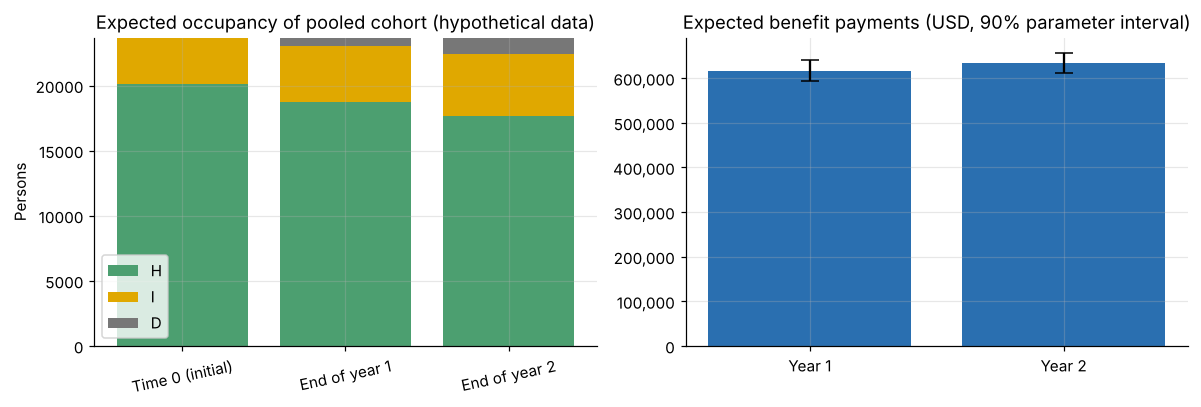

In [32]:
# What this cell does: Turns the expected number of new deaths in each year into benefit payments (USD
# 1,000 per death), adds a simulated 90% range for parameter uncertainty, and splits the result by
# district.
BENEFIT = 1000.0
deaths_y1 = n1[2] - n0[2]; deaths_y2 = n2[2] - n1[2]
claims = pd.DataFrame({'Expected deaths': [deaths_y1, deaths_y2, deaths_y1 + deaths_y2],
                       'Expected benefit payments (USD)': [BENEFIT * deaths_y1, BENEFIT * deaths_y2, BENEFIT * (deaths_y1 + deaths_y2)]}, index=['Year 1', 'Year 2', 'Total'])
print(claims.round(1).to_string())
print(f'\nCheck: total benefit = 1,000 x D(2) = {BENEFIT*n2[2]:,.1f}')
print('Alive (covered) at end of year 1 and 2:', round(n1[:2].sum(), 1), round(n2[:2].sum(), 1))

# Parameter uncertainty (Poisson/Gamma draws for each intensity) -> range for expected claims
rng = np.random.default_rng(2026)
sims = []
for _ in range(3000):
    c = {k: rng.gamma(v, 1.0) for k, v in cnt.items()}
    Qs = build_Q(c, expo)
    a, b = n0 @ expm(Qs), n0 @ expm(2 * Qs)
    sims.append([BENEFIT * a[2], BENEFIT * (b[2] - a[2])])
sims = np.array(sims); lo, hi = np.percentile(sims, [5, 95], axis=0)
print(f'\n90% interval for year-1 benefit: USD {lo[0]:,.0f} to {hi[0]:,.0f};  year-2 benefit: USD {lo[1]:,.0f} to {hi[1]:,.0f} (parameter uncertainty only)')
KEY['claims'] = dict(n0=n0.tolist(), n1=n1.tolist(), n2=n2.tolist(), y1=BENEFIT * deaths_y1, y2=BENEFIT * deaths_y2, lo=lo.tolist(), hi=hi.tolist(), P1=P1.tolist(), P2=P2.tolist())

# By-district split (initial counts of each district x pooled P): feeds the dashboard district filter and reconciles to the pooled answer
dist_rows = []
for d, g in origin_tbl.groupby('district_id'):
    v = np.array([g.loc[g.origin == 'H', 'initial_lives'].iloc[0], g.loc[g.origin == 'I', 'initial_lives'].iloc[0], 0.0])
    a1, a2 = v @ P1, v @ P2
    dist_rows.append(dict(district_id=d, initial_H=v[0], initial_I=v[1], H_end1=a1[0], I_end1=a1[1], D_end1=a1[2], H_end2=a2[0], I_end2=a2[1], D_end2=a2[2],
                          expected_deaths_y1=a1[2], expected_deaths_y2=a2[2] - a1[2], claims_y1_usd=BENEFIT * a1[2], claims_y2_usd=BENEFIT * (a2[2] - a1[2])))
claims_dist = pd.DataFrame(dist_rows)
print('\nSum over districts reconciles to pooled result:', np.isclose(claims_dist.claims_y1_usd.sum(), BENEFIT * deaths_y1), np.isclose(claims_dist.claims_y2_usd.sum(), BENEFIT * deaths_y2))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(occ.index, occ.H, label='H', color='#4c9f70'); ax[0].bar(occ.index, occ.I, bottom=occ.H, label='I', color='#e0a800'); ax[0].bar(occ.index, occ.D, bottom=occ.H + occ.I, label='D', color='#777')
ax[0].set_title(f'Expected occupancy of pooled cohort {HYP}'); ax[0].set_ylabel('Persons'); ax[0].legend(); ax[0].tick_params(axis='x', rotation=12)
ax[1].bar(['Year 1', 'Year 2'], [BENEFIT * deaths_y1, BENEFIT * deaths_y2], color='#2a6fb0', yerr=[[BENEFIT*deaths_y1-lo[0], BENEFIT*deaths_y2-lo[1]], [hi[0]-BENEFIT*deaths_y1, hi[1]-BENEFIT*deaths_y2]], capsize=6)
ax[1].set_title('Expected benefit payments (USD, 90% parameter interval)'); ax[1].yaxis.set_major_formatter(lambda v, p: f'{v:,.0f}')
fig.tight_layout(); fig.savefig(FIG / 'markov_claims.png', dpi=150)

**Notes: benefit payments.**
- **Year 1: USD 616,501** (616.5 expected deaths). **Year 2: USD 634,457** (634.5 expected deaths). Over two years that is USD 1,250,957. Year 2 is higher because the ill group grows and ill people die about 3.7 times faster than healthy people.
- The 90% range from parameter uncertainty alone is USD 593,766 to 639,731 in year 1 and USD 611,793 to 657,132 in year 2. It does not include random variation in who actually dies.
- The district split adds back to the pooled answer, as it should.
- **Limitation of pooling constant intensities:** it treats every insured person, in every district, at every age and every length of illness, as having the same rates, and it assumes the rates do not change over the two years. Real death and illness rates rise with age and depend on how long someone has been ill, and districts differ. If the real cohort is older or sicker than the pool, claims will be too low.

In [33]:
# What this cell does: Changes each of the four intensities up and down by 20% (one at a time) and
# records the effect on two-year claims.
# One-way sensitivity of expected claims to each pooled intensity (+/-20%), holding the others fixed
def claims_for(Qm):
    a, b = n0 @ expm(Qm), n0 @ expm(2 * Qm)
    return BENEFIT * a[2], BENEFIT * (b[2] - a[2])
rows = []
names_ij = {(0, 1): 'H to I (illness onset)', (0, 2): 'H to D', (1, 0): 'I to H (recovery)', (1, 2): 'I to D'}
base_c = claims_for(Q)
for (i, j), nm in names_ij.items():
    for fac in (0.8, 1.2):
        Qs = Q.copy(); Qs[i, j] *= fac; Qs[i, i] = -(Qs[i].sum() - Qs[i, i])
        c1, c2 = claims_for(Qs)
        rows.append(dict(intensity=nm, factor=fac, claims_y1=c1, claims_y2=c2, total_2yr=c1 + c2, change_vs_base_pct=100 * ((c1 + c2) / sum(base_c) - 1)))
tornado = pd.DataFrame(rows)
tornado.to_csv(OUT / 'markov_claims_sensitivity.csv', index=False)
KEY['tornado'] = tornado.round(2).to_dict('records'); KEY['claims']['base_total'] = sum(base_c)
tornado.round(1)

,intensity,factor,claims_y1,claims_y2,total_2yr,change_vs_base_pct
0,H to I (illness onset),0.8000,"607,762.5000","613,145.5000","1,220,908",-2.4000
1,H to I (illness onset),1.2000,"625,124.7000","655,140","1,280,264.7000",2.3000
2,H to D,0.8000,"547,415.8000","571,009.1000","1,118,424.8000",-10.6000
3,H to D,1.2000,"685,343.1000","697,237.1000","1,382,580.2000",10.5000
4,I to H (recovery),0.8000,"620,625.1000","645,895.6000","1,266,520.6000",1.2000
5,I to H (recovery),1.2000,"612,498.1000","623,735.1000","1,236,233.2000",-1.2000
6,I to D,0.8000,"564,155.2000","576,733.6000","1,140,888.9000",-8.8000
7,I to D,1.2000,"668,225.5000","690,440.9000","1,358,666.3000",8.6000


**Notes: which intensity drives claims?** The death rates matter far more than illness or recovery. A 20% rise in H to D increases claims by 10.5%, and a 20% rise in I to D increases them by 8.6%. The same change in illness onset moves claims by only 2.3% and in recovery by -1.2%. The reason is that 84.9% of the cohort starts healthy, so even a small healthy death rate produces most of the claims. For the insurer this means the accuracy of the two death intensities matters much more than the illness dynamics, and it is why we recommend a reserve margin.